# Real Estate Housing Price Prediction (Ridge & Lasso Regression)

## Importing the Libraries 

In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV

In [120]:
df = pd.read_csv('housing.csv')

## - EDA (Exploratory data analysis)

In [121]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [122]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


In [123]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [124]:
df.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

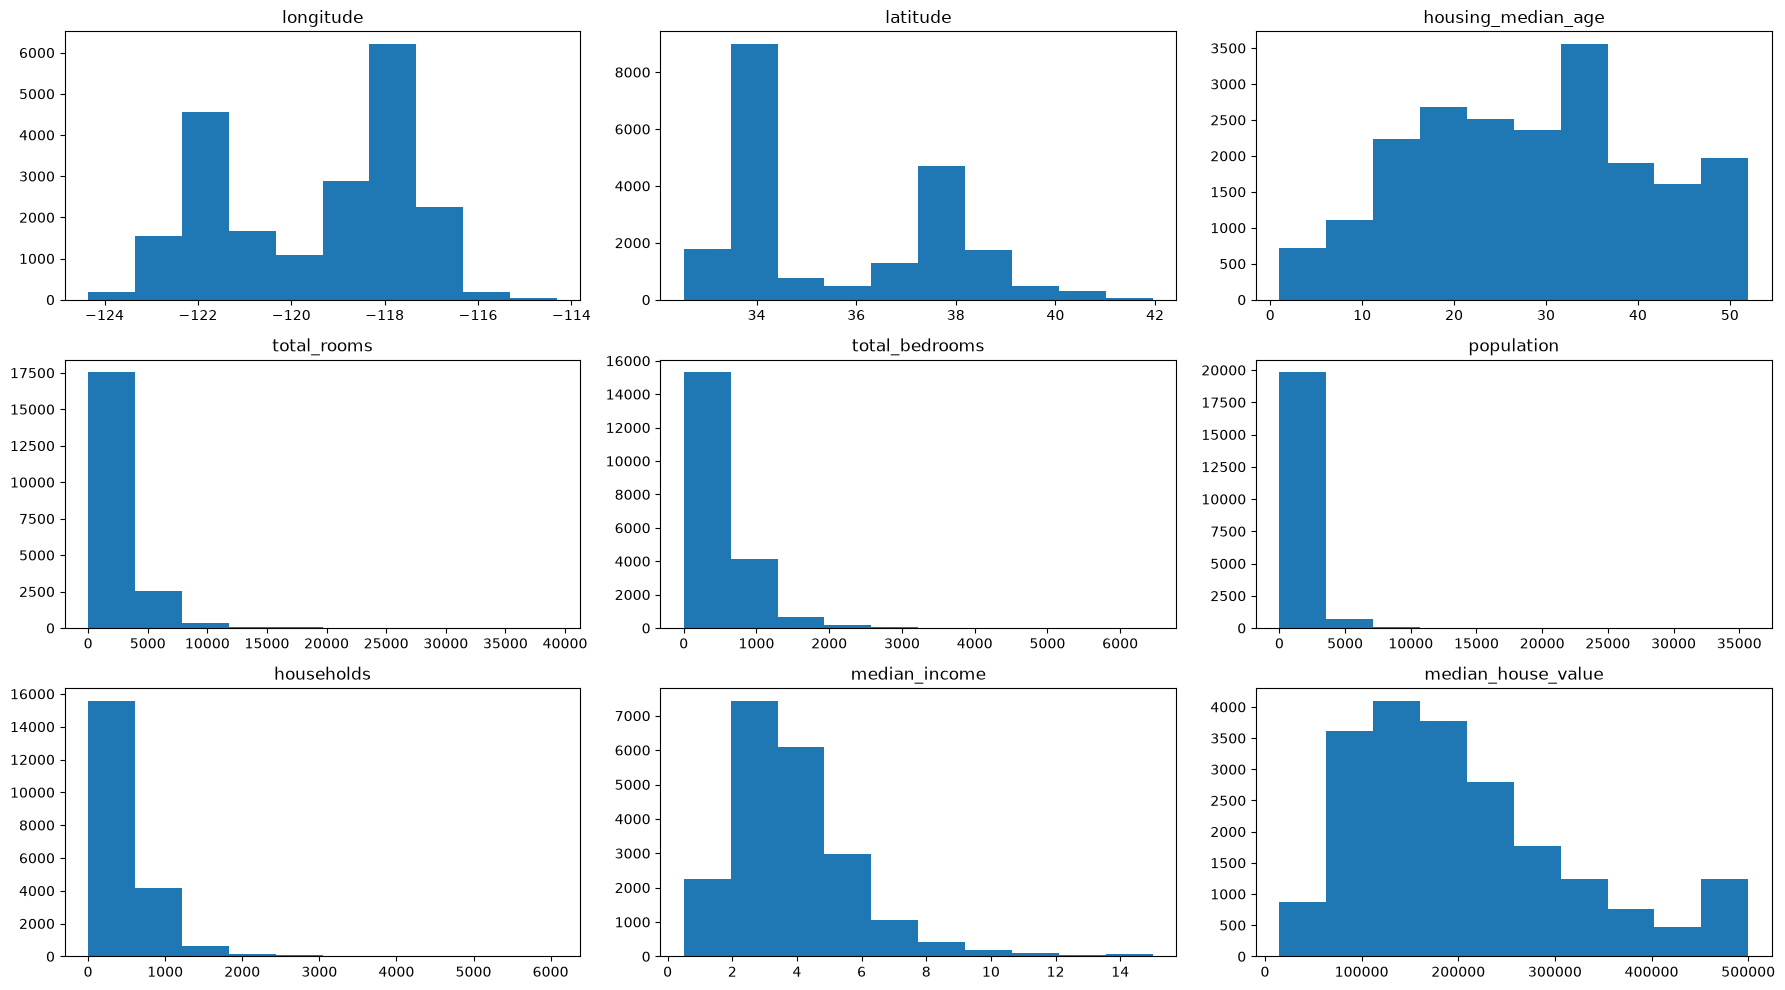

In [125]:
figure , axis = plt.subplots(3,3, figsize=(18, 10))
columns = ['longitude','latitude','housing_median_age','total_rooms','total_bedrooms','population','households','median_income','median_house_value']
i = 0
j = 0
for col in columns:
    if j == 3:
        i+=1
        j =0
    axis[i,j].hist(df[col])
    axis[i,j].set_title(col)
    j+=1
plt.savefig('Features Distribution.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

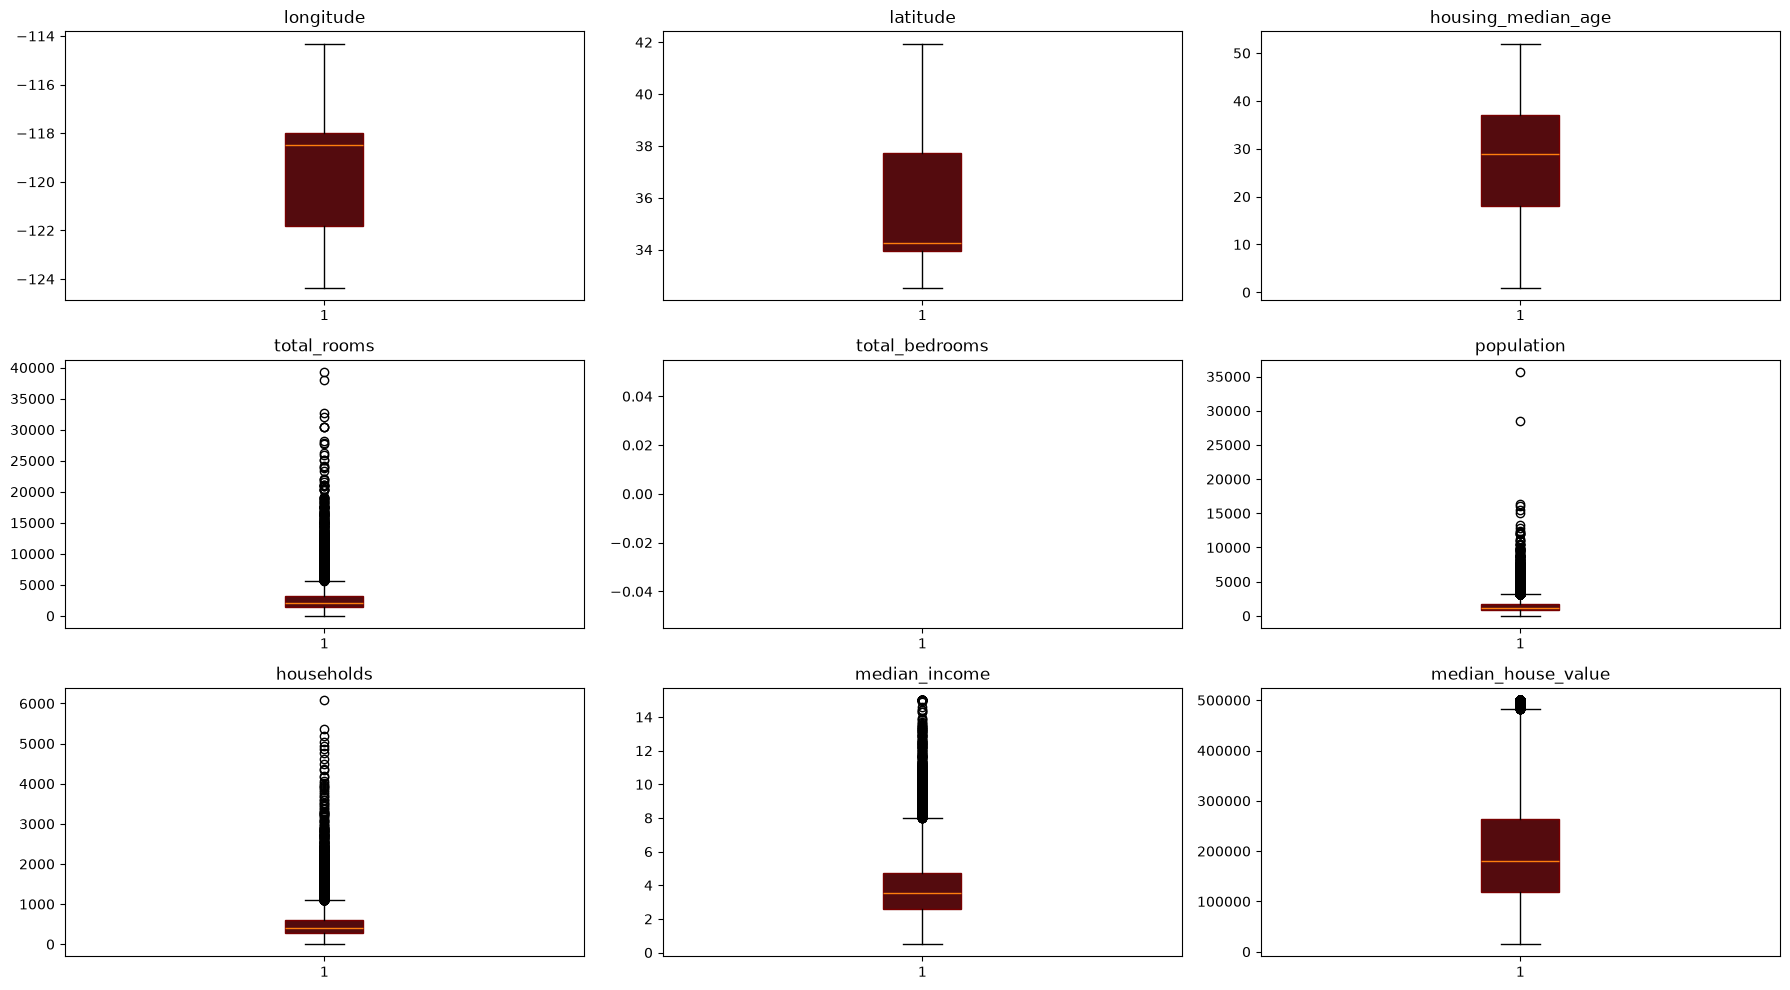

In [126]:
figure , axis = plt.subplots(3,3, figsize=(18, 10))
columns = ['longitude','latitude','housing_median_age','total_rooms','total_bedrooms','population','households','median_income','median_house_value']
i = 0
j = 0
for col in columns:
    if j == 3:
        i+=1
        j =0
    axis[i,j].boxplot(df[col], patch_artist=True, boxprops=dict(facecolor='#540b0e', color='#780000'))
    axis[i,j].set_title(col)
    j+=1
plt.savefig('Boxplot.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

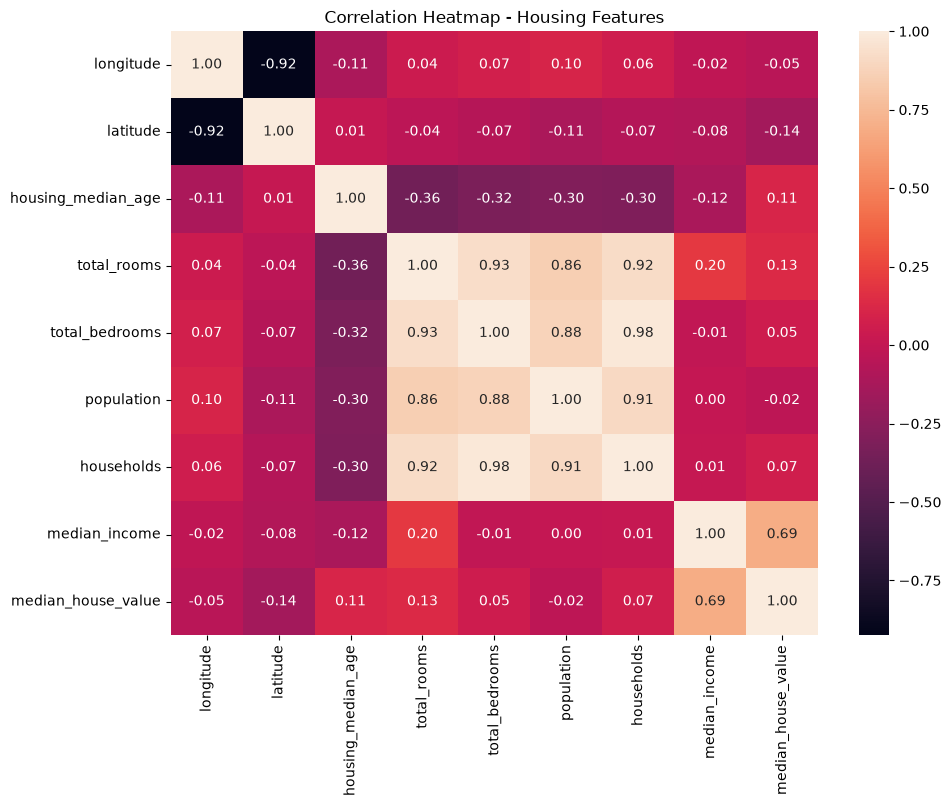

In [127]:
features = df.select_dtypes(include = 'float64')

plt.figure(figsize =(10,8))
sns.heatmap(features.corr() , annot=True, fmt='.2f')
plt.savefig('Correlation Heatmap - Housing Features.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.title("Correlation Heatmap - Housing Features")
plt.show()

## - Cleaning the data

In [128]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

In [129]:
df.isna().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [130]:
df['average_room_for_person'] = df['total_rooms'] / df['population']

In [131]:
df['rooms_per_household'] = df['total_rooms'] / df['households']

In [132]:
x = df.drop('median_house_value',axis = 1)
y = df['median_house_value']

In [133]:
le = LabelEncoder()
x.ocean_proximity = le.fit_transform(x.ocean_proximity)

In [134]:
x

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,average_room_for_person,rooms_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,3,2.732919,6.984127
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,3,2.956685,6.238137
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,3,2.957661,8.288136
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,3,2.283154,5.817352
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,3,2.879646,6.281853
...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,1,1.970414,5.045455
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,1,1.957865,6.114035
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,1,2.238332,5.205543
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,1,2.510121,5.329513


In [135]:
ohe = OneHotEncoder()
ct = ColumnTransformer([('ocean_proximity', OneHotEncoder(), [8])], remainder = 'passthrough')

In [136]:
x = ct.fit_transform(x)

In [137]:
x_train, x_test, y_train, y_test = train_test_split(x, y, 
                                                    test_size= 0.2
                                                    , random_state = 42)
print(f"input data training {x_train.shape[0]} rows and {x_train.shape[1]} columns")
print(f"output data training {y_train.shape[0]} rows ")
print(f"input data testing {x_test.shape[0]} rows and {x_test.shape[1]} columns")
print(f"output data testing {y_test.shape[0]} rows ")

input data training 16512 rows and 15 columns
output data training 16512 rows 
input data testing 4128 rows and 15 columns
output data testing 4128 rows 


In [138]:
standared = StandardScaler()
cols = ct.get_feature_names_out()

x_train_scaled = pd.DataFrame(standared.fit_transform(x_train), columns=cols)
x_test_scaled = pd.DataFrame(standared.transform(x_test), columns=cols)

In [139]:
""" 1 - Linear model training """
# Training the linear regression model 
Linear_regression_model = LinearRegression()
Linear_regression_model.fit(x_train_scaled, y_train)
Linear_model_prediction = Linear_regression_model.predict(x_test_scaled)

""" 2 - Ridge model training """

# Training the ridge model and hypertuning it using GridSearchCV
# set the alphas values 
alphas = np.logspace(-2, 3, 20)
# hyperparametertuning ridge
ridge_grid = GridSearchCV(
    Ridge(), {"alpha": alphas}, cv=5, scoring="neg_root_mean_squared_error"
)
ridge_grid.fit(x_train_scaled, y_train)
# choosing the best hyperparameters of ridge hyperparameter tuning 
best_ridge = ridge_grid.best_estimator_
# predicting from best ridge model the y_test
ridge_prediction = best_ridge.predict(x_test_scaled)

""" 3 - Laso model training """

# Training the laso model and hypertuning it using GridSearchCV

# hyperparametertuning laso
alphas = np.logspace(-1, 3, 20)
laso_grid = GridSearchCV(
    Lasso(max_iter=100000, tol=1e-2, random_state= 42),
    {"alpha": alphas},
    cv=5,
    scoring="neg_root_mean_squared_error",
)

laso_grid.fit(x_train_scaled, y_train)
best_laso = laso_grid.best_estimator_
laso_prediction = best_laso.predict(x_test_scaled)

""" - Evaluating all models """
def eval_model(name, y_true, y_pred):
  rmse = np.sqrt(mean_squared_error(y_true, y_pred))
  mae = mean_absolute_error(y_true, y_pred)
  r2 = r2_score(y_true, y_pred)
  return {"Model": name, "RMSE": rmse, "MAE": mae, "R2": r2}

print(f"{eval_model('Linear Regreesion ',y_test, Linear_model_prediction)}")
print(f"{eval_model('Ridge ',y_test, ridge_prediction)}")
print(f"{eval_model('Laso ',y_test, laso_prediction)}")

{'Model': 'Linear Regreesion ', 'RMSE': np.float64(67817.16769777387), 'MAE': 49079.79048760354, 'R2': 0.649028027820602}
{'Model': 'Ridge ', 'RMSE': np.float64(67777.48611228642), 'MAE': 49018.145838630146, 'R2': 0.6494386332831827}
{'Model': 'Laso ', 'RMSE': np.float64(67786.63145879246), 'MAE': 49044.87292320736, 'R2': 0.6493440230622853}


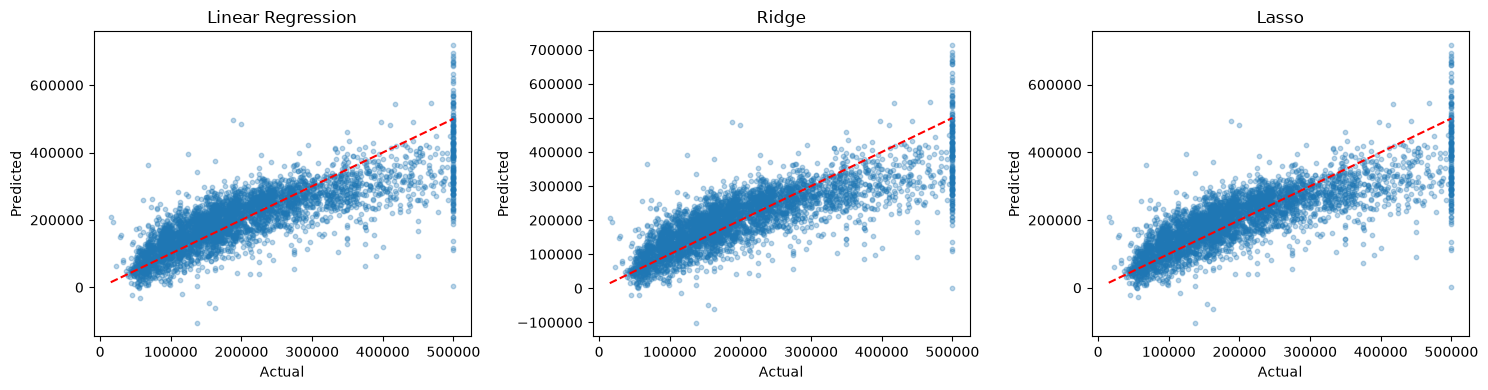

In [140]:
plt.figure(figsize=(15, 4))

# Linear Regression
plt.subplot(1, 3, 1)
plt.scatter(y_test, Linear_model_prediction, alpha=0.3, s=10)
plt.plot(
    [y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.title("Linear Regression")
plt.xlabel("Actual")
plt.ylabel("Predicted")

# Ridge
plt.subplot(1, 3, 2)
plt.scatter(y_test, ridge_prediction, alpha=0.3, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.title("Ridge")
plt.xlabel("Actual")
plt.ylabel("Predicted")

# Lasso
plt.subplot(1, 3, 3)
plt.scatter(y_test, laso_prediction, alpha=0.3, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.title("Lasso")
plt.xlabel("Actual")
plt.ylabel("Predicted")

plt.savefig('Prediction vs actual_values.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()